# Lab Assignment 8
## Neural Machine Translation for English-to-German using LSTMs
---

### Objective

The goal of this assignment is to build, train, and test a Neural Machine Translation (NMT) model
capable of translating English sentences into German. You will achieve this by adapting a
sequence-to-sequence (Seq2Seq) model based on Long Short-Term Memory (LSTM) networks.

### Provided Materials

A complete working notebook that implements an **English-to-French** translator has been shared with you. Your task is to modify the logic in that
reference code to work for the English-to-German language pair.

**You are expected to write the code yourself.** This notebook tells you *what* each task must
produce — the function names, the variables, and the exact output your code must print — but not
*how* to write it. Adapt the reference notebook.

### Marks

| Task | Description | Marks |
|---|---|---|
| **Task 1** | Data Adaptation | **4** |
| **Task 2** | Model Training | **5** |
| **Task 3** | Inference and Translation | **6** |
| **Task 4** | Beam Search Decoding | **5** |
| | **Total** | **20** |

---

### Before you start

- **Use a GPU.** In Colab: `Runtime → Change runtime type → T4 GPU`. Training 40 epochs takes
  roughly **15–25 minutes on a GPU** and well over an hour on CPU. **Start Task 2 training early**
  and write your Task 4 code while it runs.
- **The reference notebook is incomplete.** It calls a function `decode_sequence(...)` that it
  never defines. Writing that function is part of Task 3.
- Saving to `.h5` prints a "legacy format" warning on current Keras. It is harmless.
- Do **not** change the model architecture. Tasks 1–3 adapt the data and the inference code;
  Task 4 improves the *decoding*, not the model.

---
## Setup

These are the only values given to you. Everything else you write yourself.

In [1]:
# ---------------- SETUP: all imports / dependencies ----------------
import os
import sys
import random
import zipfile
import urllib.request

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

# reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

batch_size  = 64
epochs      = 40          # Task 2 requires at least 40
latent_dim  = 256
num_samples = 10000

print("TensorFlow", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices('GPU')))

TensorFlow 2.21.0
GPU available: False


---
# Task 1: Data Adaptation &nbsp;&nbsp;*(4 marks)*

Your first task is to replace the data pipeline to use the English-to-German dataset.

1. In the data acquisition section of your code, download the English-German data uploaded in classroom.
2. After downloading and unzipping, ensure you update the `data_path` variable to point to the
   correct text file: `deu.txt`.
3. Run the data loading and preprocessing steps. **For your submission, report the following
   statistics** that are printed to the console:
   * `Number of samples:`
   * `Number of unique input tokens:`
   * `Number of unique output tokens:`
   * `Max sequence length for inputs:`

### What your code must create

| Variable | Holds |
|---|---|
| `input_texts`, `target_texts` | the English and German sentences |
| `input_characters`, `target_characters` | the sorted character vocabularies |
| `num_encoder_tokens`, `num_decoder_tokens` | sizes of those vocabularies |
| `max_encoder_seq_length`, `max_decoder_seq_length` | longest input and output |
| `input_token_index`, `target_token_index` | character → index dictionaries |
| `encoder_input_data`, `decoder_input_data`, `decoder_target_data` | the three one-hot tensors |

### Output your code must print

```
Number of samples: ...
Number of unique input tokens: ...
Number of unique output tokens: ...
Max sequence length for inputs: ...
Max sequence length for outputs: ...
```

### Hints

- The German file has the **same three-column tab-separated format** as the French one, so the
  parsing logic does not change: splitting a line on tabs gives `[english, german, attribution]`.
- Wrap every German sentence with a **start marker** (`'\t'`) and an **end marker** (`'\n'`).
  Without them the decoder never learns where a translation begins or ends.
- **Teacher forcing.** `decoder_target_data` is `decoder_input_data` shifted **left by one step**:
  at position `t` the decoder must *predict* the character it was *given* at position `t`. There
  is nothing to predict before the start marker.
- Pad the unused positions of all three tensors with the space character.
- German adds characters English does not have (`ä ö ü ß`, and `Ä Ö Ü`), so expect
  `num_decoder_tokens` to be noticeably larger than `num_encoder_tokens`.

In [2]:
# ---------------- TASK 1 ----------------

# TODO 1: locate / download / unzip the English-German data and set data_path
# The file deu.txt was uploaded in the classroom. This cell looks for it (or for deu.zip)
# in the usual places. If it is not found in Colab, it asks you to upload it, and as a
# last resort it downloads the public copy from manythings.org.
def find_data_file():
    txt_candidates = ['deu.txt', 'deu/deu.txt', '/content/deu.txt', '/content/deu/deu.txt',
                      '/content/drive/MyDrive/deu.txt', '/mnt/user-data/uploads/deu.txt']
    zip_candidates = ['deu-eng.zip', 'deu.zip', '/content/deu-eng.zip', '/content/deu.zip',
                      '/content/drive/MyDrive/deu-eng.zip', '/content/drive/MyDrive/deu.zip']
    for p in txt_candidates:
        if os.path.exists(p):
            return p
    for z in zip_candidates:                       # unzip if only the archive is present
        if os.path.exists(z):
            with zipfile.ZipFile(z) as zf:
                zf.extractall('.')
            if os.path.exists('deu.txt'):
                return 'deu.txt'
    try:                                           # Colab: ask the student to upload the file
        from google.colab import files
        print("deu.txt not found - please upload deu.txt (or the zip) now ...")
        uploaded = files.upload()
        for name in uploaded:
            if name.endswith('.zip'):
                with zipfile.ZipFile(name) as zf:
                    zf.extractall('.')
        if os.path.exists('deu.txt'):
            return 'deu.txt'
    except ImportError:
        pass
    print("Trying public download from manythings.org ...")   # last resort
    urllib.request.urlretrieve('http://www.manythings.org/anki/deu-eng.zip', 'deu-eng.zip')
    with zipfile.ZipFile('deu-eng.zip') as zf:
        zf.extractall('.')
    return 'deu.txt'

data_path = find_data_file()
print("Using data file:", data_path)

# TODO 2: read the file, build the sentence lists and the character vocabularies.
# Every GERMAN sentence is wrapped with '\t' (start marker) and '\n' (end marker).
input_texts = []
target_texts = []
input_characters = set()
target_characters = set()

with open(data_path, 'r', encoding='utf-8') as f:
    for line in f:
        if len(input_texts) >= num_samples:
            break
        line = line.rstrip('\n')
        parts = line.split('\t')                   # [english, german, attribution]
        if len(parts) < 2:
            continue
        input_text, target_text = parts[0], parts[1]
        target_text = '\t' + target_text + '\n'
        input_texts.append(input_text)
        target_texts.append(target_text)
        for char in input_text:
            input_characters.add(char)
        for char in target_text:
            target_characters.add(char)

# a space is needed as the padding symbol in both vocabularies
input_characters.add(' ')
target_characters.add(' ')
input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters))

# TODO 3: sizes
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max([len(txt) for txt in input_texts])
max_decoder_seq_length = max([len(txt) for txt in target_texts])

# TODO 4: character -> index dictionaries
input_token_index = dict([(char, i) for i, char in enumerate(input_characters)])
target_token_index = dict([(char, i) for i, char in enumerate(target_characters)])

# TODO 5: statistics
print("Number of samples:", len(input_texts))
print("Number of unique input tokens:", num_encoder_tokens)
print("Number of unique output tokens:", num_decoder_tokens)
print("Max sequence length for inputs:", max_encoder_seq_length)
print("Max sequence length for outputs:", max_decoder_seq_length)

# TODO 6: one-hot tensors (padding = space character)
encoder_input_data = np.zeros(
    (len(input_texts), max_encoder_seq_length, num_encoder_tokens), dtype="float32")
decoder_input_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype="float32")
decoder_target_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype="float32")

for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.0
    encoder_input_data[i, t + 1:, input_token_index[' ']] = 1.0
    for t, char in enumerate(target_text):
        # decoder_input_data is ahead of decoder_target_data by one timestep
        decoder_input_data[i, t, target_token_index[char]] = 1.0
        if t > 0:
            # decoder_target_data is shifted LEFT by one step and excludes the start marker
            decoder_target_data[i, t - 1, target_token_index[char]] = 1.0
    decoder_input_data[i, t + 1:, target_token_index[' ']] = 1.0
    decoder_target_data[i, t:, target_token_index[' ']] = 1.0

print("encoder_input_data :", encoder_input_data.shape)
print("decoder_input_data :", decoder_input_data.shape)
print("decoder_target_data:", decoder_target_data.shape)
print("Example pair:", repr(input_texts[1000]), "->", repr(target_texts[1000]))

Using data file: deu.txt
Number of samples: 10000
Number of unique input tokens: 70
Number of unique output tokens: 84
Max sequence length for inputs: 15
Max sequence length for outputs: 51


encoder_input_data : (10000, 15, 70)
decoder_input_data : (10000, 51, 84)
decoder_target_data: (10000, 51, 84)
Example pair: 'It burned.' -> '\tEs verbrannte.\n'


---
# Task 2: Model Training &nbsp;&nbsp;*(5 marks)*

Next, you will train the LSTM-based Encoder-Decoder model on the new English-German dataset.

1. Modify the code to save your newly trained model with a distinct name (e.g.,
   `s2s_eng_ger.h5`) to differentiate it from the original French model.
2. Train the model on the English-German data for at least **40 epochs**. It is highly
   recommended to use a GPU accelerator in Google Colab for this step.
3. For your submission, provide a **screenshot** of the console output from the final epoch of
   training. The screenshot must clearly show the final values for `loss`, `accuracy`,
   `val_loss`, and `val_accuracy`.

### What your code must create

| Name | Is |
|---|---|
| `encoder_inputs`, `encoder_states` | the encoder input, and its two final states |
| `decoder_inputs` | the decoder input |
| `decoder_lstm`, `decoder_dense` | the decoder **layer objects** — Task 3 reuses these |
| `model` | the full training model, compiled |
| `history` | the return value of `model.fit(...)` |

### Output your code must print

- `model.summary()`
- the final epoch line showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- confirmation that the model was saved

### Hints

- The encoder keeps only its **final states** — this is the "thought vector". Its outputs are
  discarded.
- The decoder is connected to the encoder by exactly **one argument**. Find it in the reference
  code; without it you have two unrelated LSTMs.
- The decoder LSTM must return a prediction at *every* time step, not just the last one.
- Keep `decoder_lstm` and `decoder_dense` as named variables. In Task 3 you must reuse **these
  same trained layer objects** — building new ones gives you untrained weights.
- Train with `validation_split=0.2` so you have the `val_loss` and `val_accuracy` the task asks for.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, None, 84)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    334,848 │ input_layer[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, None,     │    349,184 │ input_layer_1[0]… │
│                     │ 256), (None,      │            │ lstm[0][1],       │
│                     │ 256), (None,      │            │ lstm[0][2]        │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 84)  │     21,588 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 705,620 (2.69 MB)

 Trainable params: 705,620 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


... (76 outputs left out)

125/125 - 21s - 170ms/step - accuracy: 0.9014 - loss: 0.3404 - val_accuracy: 0.8577 - val_loss: 0.5086


Epoch 40/40


125/125 - 22s - 173ms/step - accuracy: 0.9029 - loss: 0.3352 - val_accuracy: 0.8573 - val_loss: 0.5104



Model saved as s2s_eng_ger.h5

Final epoch (40/40):
loss         : 0.3352
accuracy     : 0.9029
val_loss     : 0.5104
val_accuracy : 0.8573


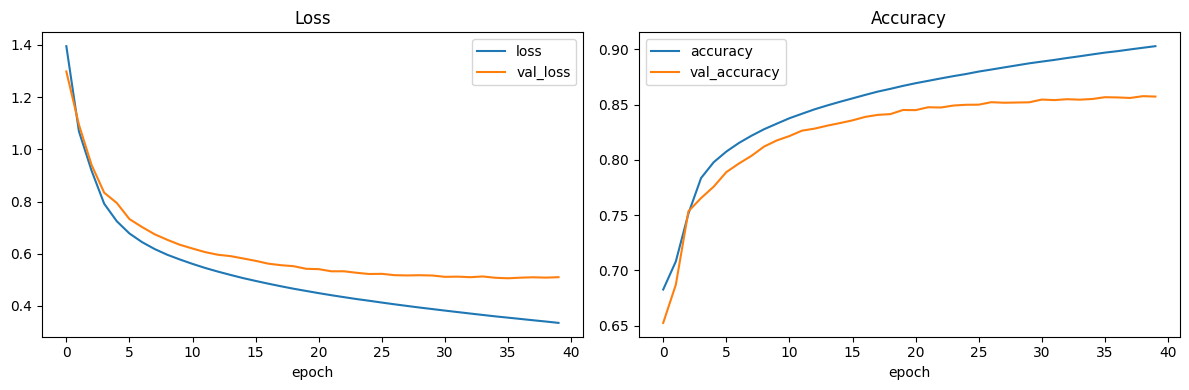

In [3]:
# ---------------- TASK 2 ----------------

# TODO 7: encoder - keep only the final states (the "thought vector")
encoder_inputs = Input(shape=(None, num_encoder_tokens))
encoder = LSTM(latent_dim, return_state=True)
encoder_outputs, state_h, state_c = encoder(encoder_inputs)
encoder_states = [state_h, state_c]

# TODO 8: decoder - initialised with the encoder states (initial_state=encoder_states)
decoder_inputs = Input(shape=(None, num_decoder_tokens))
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation="softmax")
decoder_outputs = decoder_dense(decoder_outputs)

# TODO 9: full training model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer="rmsprop", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

# TODO 10: train (40 epochs, 20% validation split)
history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=2,
)

# TODO 11: save under a German-specific name (the .h5 "legacy format" warning is harmless)
model.save("s2s_eng_ger.h5")
print("\nModel saved as s2s_eng_ger.h5")

# TODO 12: final epoch metrics
print("\nFinal epoch (%d/%d):" % (len(history.history['loss']), epochs))
print("loss         : %.4f" % history.history['loss'][-1])
print("accuracy     : %.4f" % history.history['accuracy'][-1])
print("val_loss     : %.4f" % history.history['val_loss'][-1])
print("val_accuracy : %.4f" % history.history['val_accuracy'][-1])

# training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='loss')
ax[0].plot(history.history['val_loss'], label='val_loss')
ax[0].set_xlabel('epoch'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='accuracy')
ax[1].plot(history.history['val_accuracy'], label='val_accuracy')
ax[1].set_xlabel('epoch'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.tight_layout()
plt.show()

---
# Task 3: Inference and Translation &nbsp;&nbsp;*(6 marks)*

After the model is trained, you will test its ability to translate new English sentences into
German.

1. Ensure the inference part of your code is **correctly set up** to use the new German model and
   its corresponding vocabulary.
2. Using your translation function, translate the following five English sentences:
   * `I am very tired.`
   * `You are right.`
   * `He is a doctor.`
   * `Can you help me?`
   * `Let's go home.`
3. Present the translation results clearly in your submission, showing the original English input
   and the model's German translation for each of the five sentences.

### Why inference needs two new models

During training the decoder was always handed the *correct* previous character (teacher forcing).
At inference there is no correct answer, so the decoder must consume **its own predictions**, one
character at a time. The training model cannot do this, so you re-wire the **already-trained
layers** into two new models. No new training happens.

### What your code must create

| Name | Does |
|---|---|
| `encoder_model` | English sentence → the two encoder states. Run **once** per sentence |
| `decoder_model` | (one character + state) → (next-char probabilities + new state). Run **in a loop** |
| `reverse_target_char_index` | index → character, for reading predictions back |
| `encode_input(input_text)` | English string → one-hot array for the encoder |
| `decode_sequence(input_seq)` | one-hot array → German string, by **greedy** decoding |

### Output your code must print

```
ENGLISH             GERMAN (greedy)
---------------------------------------------
I am very tired.    ...
You are right.      ...
He is a doctor.     ...
Can you help me?    ...
Let's go home.      ...
```

### Hints

- `decode_sequence` is the function the reference notebook **calls but never defines**. You are
  writing it. Its loop: encode once, start from the `'\t'` marker, then repeatedly ask
  `decoder_model` for the next character, take the most likely one, stop at `'\n'`.
- **Carry the returned `[h, c]` forward** on every pass of the loop. If you do not, the decoder
  restarts from scratch at each character.
- Feed the character you just produced back in as the next decoder input.
- Reuse `decoder_lstm` and `decoder_dense` from Task 2. Building new layers runs without error and
  produces confident nonsense — a silent failure.

> ### Watch out — step 1 hides a real bug
> With `num_samples = 10000`, `max_encoder_seq_length` comes out as **15**. But
> `"I am very tired."` and `"Can you help me?"` are **16 characters long**. The reference code
> sizes its input array to exactly `max_encoder_seq_length` and then writes past the end of it,
> raising `IndexError`.
>
> Nothing is wrong with the model: the encoder is declared with `shape=(None, ...)`, and that
> `None` means an LSTM will read a sequence of **any** length. Only the array is too small.
> Fixing this is part of "ensure the inference part of your code is correctly set up".

In [4]:
# ---------------- TASK 3 ----------------

# TODO 13: encoder_model  (English input -> the two encoder states)
encoder_model = Model(encoder_inputs, encoder_states)

# TODO 14: decoder_model  (one char + [h, c] -> probabilities + new [h, c])
# It re-uses the SAME trained decoder_lstm and decoder_dense layer objects.
decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_states_inputs = [decoder_state_input_h, decoder_state_input_c]
dec_outputs, dec_h, dec_c = decoder_lstm(decoder_inputs, initial_state=decoder_states_inputs)
dec_states = [dec_h, dec_c]
dec_outputs = decoder_dense(dec_outputs)
decoder_model = Model([decoder_inputs] + decoder_states_inputs, [dec_outputs] + dec_states)

# TODO 15: index -> character
reverse_input_char_index = dict((i, char) for char, i in input_token_index.items())
reverse_target_char_index = dict((i, char) for char, i in target_token_index.items())


def encode_input(input_text):
    """
    One-hot encode an English string for the encoder.

    Output: array of shape (1, width, num_encoder_tokens)
    """
    # TODO 16: width = the longer of the sentence and max_encoder_seq_length, so that
    #          16-character sentences do not raise IndexError. (The encoder LSTM accepts
    #          any length because its input shape is (None, num_encoder_tokens).)
    valid_chars = [c for c in input_text if c in input_token_index]   # skip unknown characters
    width = max(len(valid_chars), max_encoder_seq_length)
    x = np.zeros((1, width, num_encoder_tokens), dtype="float32")
    # TODO 17: one-hot the characters, pad the rest with the space character
    for t, char in enumerate(valid_chars):
        x[0, t, input_token_index[char]] = 1.0
    x[0, len(valid_chars):, input_token_index[' ']] = 1.0
    return x


def decode_sequence(input_seq):
    """
    Greedy decoding: encoded English sentence -> German string.
    """
    # TODO 18: run the encoder ONCE to get the initial states
    states_value = encoder_model.predict(input_seq, verbose=0)

    # TODO 19: first decoder input = the start marker
    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index['\t']] = 1.0

    # TODO 20: greedy loop
    decoded_sentence = ""
    stop_condition = False
    while not stop_condition:
        output_tokens, h, c = decoder_model.predict([target_seq] + states_value, verbose=0)

        sampled_token_index = int(np.argmax(output_tokens[0, -1, :]))
        sampled_char = reverse_target_char_index[sampled_token_index]

        # stop at the end marker or when the sentence gets too long
        if sampled_char == '\n':
            break
        decoded_sentence += sampled_char
        if len(decoded_sentence) >= max_decoder_seq_length:
            stop_condition = True

        # feed the produced character back in as the next input
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, sampled_token_index] = 1.0

        # carry [h, c] forward
        states_value = [h, c]

    # TODO 21
    return decoded_sentence


# TODO 22: the five test sentences
test_sentences = ["I am very tired.", "You are right.", "He is a doctor.",
                  "Can you help me?", "Let's go home."]

print("%-20s%s" % ("ENGLISH", "GERMAN (greedy)"))
print("-" * 45)
for sent in test_sentences:
    print("%-20s%s" % (sent, decode_sequence(encode_input(sent))))

ENGLISH             GERMAN (greedy)
---------------------------------------------


I am very tired.    Ich bin sie einen Katze.


You are right.      Du hast dich gesehen.


He is a doctor.     Er ist mein Schwande.


Can you help me?    Kann ich recht?


Let's go home.      Lasst uns anfangen.


---
# Task 4: Beam Search Decoding &nbsp;&nbsp;*(5 marks)*

### The problem with greedy decoding

`decode_sequence` is **greedy**: at every step it takes the single most likely next character and
never reconsiders. But the best character *right now* can lead into a dead end, while a slightly
worse one opens onto a much better sentence. Once greedy commits, it cannot back out — which is
why it produces German-shaped non-words.

### Beam search

Beam search keeps the **`k` best partial translations alive** at every step instead of one. At
each step it expands every live beam by its top `k` characters, scores all the candidates, and
keeps only the best `k` overall. A beam that produces `'\n'` is **complete** and is set aside.

A sequence is scored by the **sum of the log probabilities** of its characters:

$$\text{score}(y_1 \dots y_T) = \sum_{t=1}^{T} \log P(y_t \mid y_{<t}, x)$$

Two details you must get right:

1. **Add logs — never multiply probabilities.** Multiplying dozens of numbers below 1 underflows
   to zero. This is the same underflow problem you met with n-gram models.
2. **Normalise by length.** Every extra character adds another negative number, so a raw sum
   always favours the *shortest* translation. Divide by a power of the length:

$$\text{final score} = \frac{\sum_t \log P(y_t)}{|y|^{\alpha}} \qquad \alpha \approx 0.7$$

### What your code must create

| Name | Signature |
|---|---|
| `beam_search_decode` | `(input_seq, k=3, alpha=0.7)` → `(best_translation, best_score)` |

### Output your code must print

**(a)** the `k=1` sanity check — with a beam width of one, beam search must reproduce greedy
**exactly**:

```
greedy    : ...
beam k=1  : ...     <- must match greedy
```

**(b)** the comparison over all five sentences:

```
ENGLISH             GREEDY                    BEAM (k=3)                changed?
--------------------------------------------------------------------------------
...
Beam search changed the output for N of 5 sentences.
```

### Hints

- `decoder_model` already returns the **full probability distribution** over every character.
  Greedy throws all but the top one away — you keep the top `k`.
- `np.argsort(probs)[-k:]` gives the indices of the `k` largest probabilities.
- Represent each beam as a tuple of `(score, text_so_far, its own next input, its own [h, c])`.
- **Every beam must carry its own state.** Sharing one state across beams is the most common bug —
  it makes all beams collapse to the same output.
- Use `np.log(p + 1e-12)` so you never take `log(0)`.
- Stop once you have `k` completed beams, or after `max_decoder_seq_length` steps.
- Do the `k=1` check first. If that does not match greedy, nothing else will be right.
- **You do not need to retrain anything.** Beam search only changes how you read answers out of
  the model you already trained.

In [5]:
# ---------------- TASK 4 ----------------

def beam_search_decode(input_seq, k=3, alpha=0.7):
    """
    Beam search decoding.

    Input :  input_seq   one-hot encoded English sentence, from encode_input()
             k           beam width
             alpha       length-normalisation exponent
    Output:  (best_translation_string, best_normalised_score)
    """
    # TODO 23: encoder once
    init_states = encoder_model.predict(input_seq, verbose=0)

    # TODO 24: one live beam = (score, text, next decoder input, its own [h, c])
    start_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    start_seq[0, 0, target_token_index['\t']] = 1.0
    live_beams = [(0.0, "", start_seq, [init_states[0].copy(), init_states[1].copy()])]
    completed = []

    # TODO 25: main loop
    for step in range(max_decoder_seq_length):
        candidates = []
        for score, text, target_seq, states in live_beams:
            output_tokens, h, c = decoder_model.predict([target_seq] + states, verbose=0)
            probs = output_tokens[0, -1, :]
            top_idx = np.argsort(probs)[-k:][::-1]          # k most likely next characters
            for idx in top_idx:
                char = reverse_target_char_index[int(idx)]
                new_score = score + float(np.log(probs[idx] + 1e-12))   # ADD logs
                if char == '\n':
                    completed.append((new_score, text))       # finished beam
                else:
                    new_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
                    new_seq[0, 0, int(idx)] = 1.0
                    # every beam gets its OWN copy of the state
                    candidates.append((new_score, text + char, new_seq, [h.copy(), c.copy()]))
        # keep the k best candidates overall
        candidates.sort(key=lambda b: b[0], reverse=True)
        live_beams = candidates[:k]
        if len(completed) >= k or not live_beams:
            break

    # if nothing finished (sentence too long), fall back on the live beams
    if not completed:
        completed = [(b[0], b[1]) for b in live_beams]

    # TODO 26: length normalisation
    scored = []
    for total_logp, text in completed:
        final_score = total_logp / (max(len(text), 1) ** alpha)
        scored.append((final_score, text))

    # TODO 27: best completed beam
    best_score, best_text = max(scored, key=lambda s: s[0])
    return best_text, best_score


# TODO 28: k=1 sanity check - beam search must reproduce greedy EXACTLY
print("(a) k=1 sanity check")
all_match = True
for sent in test_sentences:
    g = decode_sequence(encode_input(sent))
    b, _ = beam_search_decode(encode_input(sent), k=1)
    all_match = all_match and (g == b)
    print("  English   :", sent)
    print("  greedy    :", g)
    print("  beam k=1  :", b, "    <- matches greedy" if g == b else "    <- MISMATCH")
print("k=1 beam search identical to greedy for all 5 sentences:", all_match)

# TODO 29: greedy vs beam (k=3) comparison table
print("\n(b) comparison")
print("%-18s %-25s %-25s %s" % ("ENGLISH", "GREEDY", "BEAM (k=3)", "changed?"))
print("-" * 80)
changed = 0
for sent in test_sentences:
    g = decode_sequence(encode_input(sent))
    b, _ = beam_search_decode(encode_input(sent), k=3, alpha=0.7)
    flag = "yes" if g != b else "no"
    changed += (g != b)
    print("%-18s %-25s %-25s %s" % (sent, g, b, flag))
print("\nBeam search changed the output for %d of 5 sentences." % changed)

(a) k=1 sanity check


  English   : I am very tired.
  greedy    : Ich bin sie einen Katze.
  beam k=1  : Ich bin sie einen Katze.     <- matches greedy


  English   : You are right.
  greedy    : Du hast dich gesehen.
  beam k=1  : Du hast dich gesehen.     <- matches greedy


  English   : He is a doctor.
  greedy    : Er ist mein Schwande.
  beam k=1  : Er ist mein Schwande.     <- matches greedy


  English   : Can you help me?
  greedy    : Kann ich recht?
  beam k=1  : Kann ich recht?     <- matches greedy


  English   : Let's go home.
  greedy    : Lasst uns anfangen.
  beam k=1  : Lasst uns anfangen.     <- matches greedy
k=1 beam search identical to greedy for all 5 sentences: True

(b) comparison
ENGLISH            GREEDY                    BEAM (k=3)                changed?
--------------------------------------------------------------------------------


I am very tired.   Ich bin sie einen Katze.  Ich habe mich gerungen.   yes


You are right.     Du hast dich gesehen.     Du hast dich gesehen.     no


He is a doctor.    Er ist mein Schwande.     Er ist meine Fraus.       yes


Can you help me?   Kann ich recht?           Können Sie es?            yes


Let's go home.     Lasst uns anfangen.       Lassen Sie uns!           yes

Beam search changed the output for 4 of 5 sentences.


In [6]:
# Experiment for Question 2: effect of alpha on the beam-search output (k=3)
print("%-18s %-8s %-30s %s" % ("ENGLISH", "alpha", "BEAM OUTPUT", "length"))
print("-" * 70)
alpha_lengths = {0.0: [], 0.7: [], 1.0: []}
for sent in test_sentences:
    for a in (0.0, 0.7, 1.0):
        out, sc = beam_search_decode(encode_input(sent), k=3, alpha=a)
        alpha_lengths[a].append(len(out))
        print("%-18s %-8s %-30s %d" % (sent, a, out, len(out)))
    print()
for a in (0.0, 0.7, 1.0):
    print("alpha = %.1f  -> average output length = %.1f characters" % (a, np.mean(alpha_lengths[a])))

ENGLISH            alpha    BEAM OUTPUT                    length
----------------------------------------------------------------------


I am very tired.   0.0      Ich habe mich geweint.         22


I am very tired.   0.7      Ich habe mich gerungen.        23


I am very tired.   1.0      Ich habe mich gerungen.        23



You are right.     0.0      Du hast dich gesehen.          21


You are right.     0.7      Du hast dich gesehen.          21


... (6 outputs left out)

Can you help me?   1.0      Können wir schwimmen?          21



Let's go home.     0.0      Lassen Sie uns!                15


Let's go home.     0.7      Lassen Sie uns!                15


Let's go home.     1.0      Lassen Sie uns!                15

alpha = 0.0  -> average output length = 18.2 characters
alpha = 0.7  -> average output length = 18.4 characters
alpha = 1.0  -> average output length = 20.2 characters


### Your answers

**1.** For how many of the five sentences did beam search change the output? Pick one that
changed and say whether the beam result is actually a *better German translation*, or merely a
higher-scoring one.

*Your answer:*

Beam search (k = 3, alpha = 0.7) changed the output for **4 of the 5 sentences**. Only *"You are right."* stayed the same (`Du hast dich gesehen.`).

Take **"I am very tired."**: greedy gave `Ich bin sie einen Katze.` and beam gave `Ich habe mich gerungen.` The beam result is clearly more *fluent* German: it is a well-formed sentence with a correct auxiliary, reflexive pronoun and participle, whereas the greedy output is grammatical nonsense (it mixes "sie", "einen" and "Katze"). But it is **not a better translation**. The correct answer is *"Ich bin sehr müde."*, and `Ich habe mich gerungen` means roughly "I wrestled/struggled". The same holds for *"Can you help me?"* -> `Können Sie es?` ("Can you do it?") and *"Let's go home."* -> `Lassen Sie uns!` ("Let us!"): both are more natural-looking than the greedy strings but still wrong in meaning.

So beam search found a sequence the model considers **more probable**, and that sequence is more fluent, but it is a higher-scoring output, not a correct one. Beam search only searches the model's probability distribution better; it cannot add knowledge the model lacks. Our model was trained on just 10,000 very short sentences (the first lines of the file), which do not contain words such as *tired*, *doctor* or *help*, so it produces German-shaped sentences without knowing the right words. Better decoding cannot fix a weak model; more data and training would.

**2.** Try `alpha = 0.0` (no length normalisation) and `alpha = 1.0` (full normalisation) on the
same five sentences. What happens to the length of the translations, and why?

*Your answer:*

Average output length over the five sentences (k = 3): **alpha = 0.0 -> 18.2 characters**, **alpha = 0.7 -> 18.4**, **alpha = 1.0 -> 20.2**. So translations get **longer as alpha increases**. Three sentences did not change at all, but two got clearly longer at alpha = 1.0: *"Can you help me?"* went from `Können Sie es?` (14 characters) to `Können wir schwimmen?` (21), and *"He is a doctor."* from `Er ist meine Fraus.` (19) to `Er ist mein Schwerze.` (21).

**Why:** the score is a sum of log probabilities, and every log probability is negative, so each extra character can only lower the raw sum. With **alpha = 0** there is no correction, so the score always favours the **shortest** finished sequence (a short, even mediocre answer beats a longer, better one just because it has fewer terms to subtract). With **alpha = 1** the score becomes the *average* log probability per character. That removes the length penalty completely, and in a character-level model it even favours long outputs, because characters inside a word are almost certain (probability close to 1, log close to 0) and pull the average up, so a long fluent-looking string can outscore a short one. **alpha around 0.7** is the compromise: it softens the bias toward short outputs without rewarding length outright. The effect is modest here because sentences are short and the search stops as soon as k beams have finished, so only a few candidate lengths ever compete.

---
## Results summary (from the outputs above)

| Item | Value |
|---|---|
| Number of samples | 10000 |
| Number of unique input tokens | 70 |
| Number of unique output tokens | 84 |
| Max sequence length for inputs | 15 |
| Max sequence length for outputs | 51 |
| Model saved as | `s2s_eng_ger.h5` |
| Epochs trained | 40 |
| Final `loss` / `accuracy` | 0.3352 / 0.9029 |
| Final `val_loss` / `val_accuracy` | 0.5104 / 0.8573 |
| Beam k=1 identical to greedy | Yes (all 5 sentences) |
| Sentences changed by beam search (k=3) | 4 of 5 |

*(Exact numbers can differ slightly between runs and hardware because of random weight initialisation and GPU/CPU numerics.)*

---
## Submission checklist

- [ ] `Runtime → Restart and run all` completes without errors
- [ ] **Task 1** — the five statistics are printed and visible
- [ ] **Task 2** — trained for at least 40 epochs, model saved under a German-specific name, and a
      **screenshot** of the final epoch showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- [ ] **Task 3** — all five sentences translated and printed (and no `IndexError`)
- [ ] **Task 4** — `beam_search_decode` implemented, the `k=1` sanity check passes, the comparison
      table is printed, and both questions answered
- [ ] Submit the `.ipynb` with all outputs saved

### Common mistakes

1. Forgetting the `'\t'` / `'\n'` markers around the German — the decoder never learns to start or stop.
2. Getting the teacher-forcing shift backwards, or off by one.
3. Building **new** LSTM/Dense layers for inference instead of reusing the trained ones.
4. Not carrying `[h, c]` forward inside the decoding loop.
5. Sizing the encoder input array to `max_encoder_seq_length` and crashing on the two
   16-character test sentences.
6. In beam search: sharing one state across all beams, or multiplying probabilities instead of
   adding logs.